# Poda Alfa-Beta en un árbol representado con listas de Python

Este cuaderno implementa un algoritmo de poda alfa-beta para un árbol de decisión representado como listas anidadas. La lista del árbol puede configurarse en la segunda celda de código.


- Un valor entero es una hoja.
- Una lista representa un nodo con hijos.
- El nodo raíz es un máximo.
- Los niveles alternan máximo y mínimo.

In [17]:
import random
import matplotlib.pyplot as plt
import networkx as nx

In [18]:
def generate_random_tree(levels, leaf_nodes, min_value=-10, max_value=10, seed=None):
    
    rng = random.Random(seed)
    if levels <= 1 or leaf_nodes <= 1:
        return [rng.randint(min_value, max_value) for _ in range(leaf_nodes)]

    branches = max(2, min(5, leaf_nodes))
    base = leaf_nodes // branches
    remainder = leaf_nodes % branches
    counts = [base + (1 if i < remainder else 0) for i in range(branches)]

    children = []
    for count in counts:
        if count == 0:
            continue
        if levels == 2:
            children.append([rng.randint(min_value, max_value) for _ in range(count)])
        else:
            next_seed = rng.randint(0, 10**9)
            children.append(generate_random_tree(levels - 1, count, min_value, max_value, next_seed))
    return children

# Configuración del árbol. Modifica esta lista o usa un árbol aleatorio.
tree = [ [3, -5, 2],[-5, -7, 4],[-9, 6, -8],]

# Ejemplo aleatorio:
#tree = generate_random_tree(levels=4, leaf_nodes=12, seed=42)

In [19]:
def is_leaf(node):
    return isinstance(node, (int, float))

def alpha_beta(node, depth=0, alpha=-float('inf'), beta=float('inf'), path=()):
    """Evalúa el subárbol usando poda alfa-beta.
    Devuelve: (valor, ruta_óptima_hasta_hoja, ramas_podadas)
    """
    if is_leaf(node):
        return float(node), path, []

    if depth % 2 == 0:  # MAX
        best_value = -float('inf')
        best_path = ()
        pruned = []

        for idx, child in enumerate(node):
            child_value, child_path, child_pruned = alpha_beta(child, depth + 1, alpha, beta, path + (idx,))

            if child_value > best_value:
                best_value = child_value
                best_path = child_path

            alpha = max(alpha, best_value)
            if beta <= alpha:
                pruned.append({'node': path + (idx,), 'reason': 'corte por beta'})
                break

        return best_value, best_path, pruned

    # MIN
    best_value = float('inf')
    best_path = ()
    pruned = []

    for idx, child in enumerate(node):
        child_value, child_path, child_pruned = alpha_beta(child, depth + 1, alpha, beta, path + (idx,))

        if child_value < best_value:
            best_value = child_value
            best_path = child_path

        beta = min(beta, best_value)
        if beta <= alpha:
            pruned.append({'node': path + (idx,), 'reason': 'corte por alfa'})
            break

    return best_value, best_path, pruned

def build_tree_graph(tree, optimal_route=(), pruned_routes=()):
    G = nx.DiGraph()
    optimal_prefixes = set()
    for i in range(1, len(optimal_route) + 1):
        optimal_prefixes.add(optimal_route[:i])

    pruned_set = set(pruned_routes)

    def add_node(node, path=()):
        node_id = path if path else ('root',)
        if is_leaf(node):
            G.add_node(node_id, depth=len(path), kind='leaf', label=str(node))
        else:
            G.add_node(node_id, depth=len(path), kind='internal', label='MAX' if len(path) % 2 == 0 else 'MIN')
            for idx, child in enumerate(node):
                child_id = path + (idx,)
                G.add_edge(node_id, child_id)
                add_node(child, child_id)

    add_node(tree)

    colors = []
    for node in G.nodes():
        if node in pruned_set:
            colors.append('tomato')
        elif node in optimal_prefixes:
            colors.append('limegreen')
        elif G.nodes[node]['kind'] == 'leaf':
            colors.append('skyblue')
        else:
            colors.append('lightgray')

    pos = nx.multipartite_layout(G, subset_key='depth', align='vertical')
    return G, pos, colors

def mostrar_resultado(tree):
    valor, ruta_optima, ramas_podadas = alpha_beta(tree)
    pruned_routes = [item['node'] for item in ramas_podadas]
    G, pos, colors = build_tree_graph(tree, ruta_optima, pruned_routes)

    print(f'Valor minimax con poda alfa-beta: {valor}')
    print(f'Ruta óptima de decisión: {ruta_optima}')
    print('Ramas podadas:')
    for item in ramas_podadas:
        print(f"  - Nodo: {item['node']} | motivo: {item['reason']}")

    fig, ax = plt.subplots(figsize=(12, 8))
    nx.draw(
        G,
        pos,
        with_labels=True,
        labels={node: G.nodes[node]['label'] for node in G.nodes()},
        node_color=colors,
        node_size=2200,
        edge_color='gray',
        font_size=10,
        ax=ax
    )
    ax.set_title('Poda Alfa-Beta: secuencia óptima y ramas podadas')
    plt.show()

    return valor, ruta_optima, ramas_podadas

Valor minimax con poda alfa-beta: -5.0
Ruta óptima de decisión: (0, 1)
Ramas podadas:


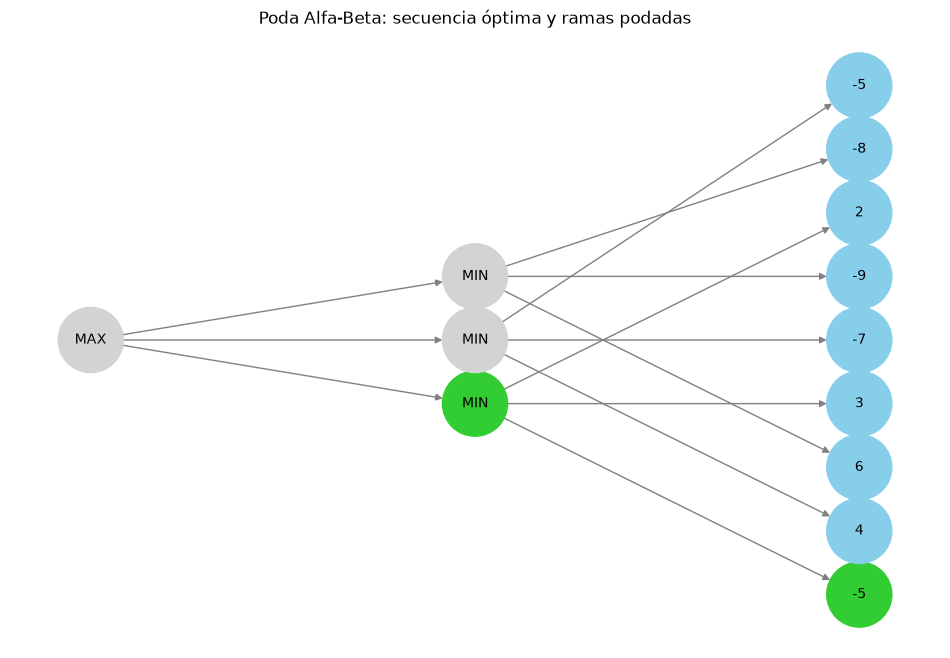

In [20]:
valor, ruta, podadas = mostrar_resultado(tree)